<a href="https://colab.research.google.com/github/Mauss57/ProyectoFinal/blob/Bitacora%2FMaria/Proyecto_Final_Heart_Failure.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    '/content/Heart_failure_clinical_records_dataset.csv',
    sep=';'
)

df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0.0,582.0,0.0,20.0,1.0,265000.00,1.9,130.0,1.0,0.0,4.0,1.0
1,55.0,0.0,7861.0,0.0,38.0,0.0,263358.03,1.1,136.0,1.0,0.0,6.0,1.0
2,65.0,0.0,146.0,0.0,20.0,0.0,162000.00,1.3,129.0,1.0,1.0,7.0,1.0
3,50.0,1.0,111.0,0.0,20.0,0.0,210000.00,1.9,137.0,1.0,0.0,7.0,1.0
4,65.0,1.0,160.0,1.0,20.0,0.0,327000.00,2.7,116.0,0.0,0.0,8.0,1.0


In [2]:
print("Tamaño de la base de datos:")
print(df.shape)

print("\nColumnas:")
print(df.columns.tolist())

print("\nInformación general:")
df.info()



Tamaño de la base de datos:
(334, 13)

Columnas:
['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time', 'DEATH_EVENT']

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 334 entries, 0 to 333
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    float64
 2   creatinine_phosphokinase  299 non-null    float64
 3   diabetes                  299 non-null    float64
 4   ejection_fraction         299 non-null    float64
 5   high_blood_pressure       299 non-null    float64
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    float64
 9   sex                  

In [3]:
# Eliminar filas completamente vacías
df = df.dropna(how='all')

# Reiniciar los índices
df = df.reset_index(drop=True)

# Revisar el nuevo tamaño
print("Tamaño después de eliminar filas vacías:")
print(df.shape)

df.head()



Tamaño después de eliminar filas vacías:
(299, 13)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0.0,582.0,0.0,20.0,1.0,265000.00,1.9,130.0,1.0,0.0,4.0,1.0
1,55.0,0.0,7861.0,0.0,38.0,0.0,263358.03,1.1,136.0,1.0,0.0,6.0,1.0
2,65.0,0.0,146.0,0.0,20.0,0.0,162000.00,1.3,129.0,1.0,1.0,7.0,1.0
3,50.0,1.0,111.0,0.0,20.0,0.0,210000.00,1.9,137.0,1.0,0.0,7.0,1.0
4,65.0,1.0,160.0,1.0,20.0,0.0,327000.00,2.7,116.0,0.0,0.0,8.0,1.0


In [4]:
print("Filas duplicadas:")
print(df.duplicated().sum())



Filas duplicadas:
0


In [5]:
print(df.isnull().sum())


age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64


In [6]:
df.describe()


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
count,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.00000,299.000000,299.000000,299.00000,299.000000,299.00000
mean,60.837237,0.431438,581.839465,0.418060,38.083612,0.351171,263358.029264,1.39388,136.625418,0.648829,0.32107,130.260870,0.32107
std,11.900919,0.496107,970.287881,0.494067,11.834841,0.478136,97804.236869,1.03451,4.412477,0.478136,0.46767,77.614208,0.46767
min,40.000000,0.000000,23.000000,0.000000,14.000000,0.000000,25100.000000,0.50000,113.000000,0.000000,0.00000,4.000000,0.00000
25%,51.000000,0.000000,116.500000,0.000000,30.000000,0.000000,212500.000000,0.90000,134.000000,0.000000,0.00000,73.000000,0.00000
50%,60.000000,0.000000,250.000000,0.000000,38.000000,0.000000,262000.000000,1.10000,137.000000,1.000000,0.00000,115.000000,0.00000
75%,70.000000,1.000000,582.000000,1.000000,45.000000,1.000000,303500.000000,1.40000,140.000000,1.000000,1.00000,203.000000,1.00000
max,95.000000,1.000000,7861.000000,1.000000,80.000000,1.000000,850000.000000,9.40000,148.000000,1.000000,1.00000,285.000000,1.00000


In [7]:
# Variables clínicas que vamos a revisar
variables = [
    'age',
    'creatinine_phosphokinase',
    'ejection_fraction',
    'platelets',
    'serum_creatinine',
    'serum_sodium'
]

for columna in variables:
    Q1 = df[columna].quantile(0.25)
    Q3 = df[columna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    extremos = df[
        (df[columna] < limite_inferior) |
        (df[columna] > limite_superior)
    ]

    print(f"\nVariable: {columna}")
    print("Posibles valores extremos:", len(extremos))
    print("Límite inferior:", round(limite_inferior, 2))
    print("Límite superior:", round(limite_superior, 2))




Variable: age
Posibles valores extremos: 0
Límite inferior: 22.5
Límite superior: 98.5

Variable: creatinine_phosphokinase
Posibles valores extremos: 29
Límite inferior: -581.75
Límite superior: 1280.25

Variable: ejection_fraction
Posibles valores extremos: 2
Límite inferior: 7.5
Límite superior: 67.5

Variable: platelets
Posibles valores extremos: 21
Límite inferior: 76000.0
Límite superior: 440000.0

Variable: serum_creatinine
Posibles valores extremos: 29
Límite inferior: 0.15
Límite superior: 2.15

Variable: serum_sodium
Posibles valores extremos: 4
Límite inferior: 125.0
Límite superior: 149.0


In [8]:
variables_categoricas = [
    'anaemia',
    'diabetes',
    'high_blood_pressure',
    'sex',
    'smoking',
    'DEATH_EVENT'
]

for columna in variables_categoricas:
    print(f"\n{columna}")
    print(df[columna].value_counts())



anaemia
anaemia
0.0    170
1.0    129
Name: count, dtype: int64

diabetes
diabetes
0.0    174
1.0    125
Name: count, dtype: int64

high_blood_pressure
high_blood_pressure
0.0    194
1.0    105
Name: count, dtype: int64

sex
sex
1.0    194
0.0    105
Name: count, dtype: int64

smoking
smoking
0.0    203
1.0     96
Name: count, dtype: int64

DEATH_EVENT
DEATH_EVENT
0.0    203
1.0     96
Name: count, dtype: int64


In [9]:
variables_binarias = [
    'anaemia',
    'diabetes',
    'high_blood_pressure',
    'sex',
    'smoking',
    'DEATH_EVENT'
]

for columna in variables_binarias:
    df[columna] = df[columna].astype(int)

df[variables_binarias].info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   anaemia              299 non-null    int64
 1   diabetes             299 non-null    int64
 2   high_blood_pressure  299 non-null    int64
 3   sex                  299 non-null    int64
 4   smoking              299 non-null    int64
 5   DEATH_EVENT          299 non-null    int64
dtypes: int64(6)
memory usage: 14.1 KB


In [10]:
df.to_csv(
    '/content/Heart_failure_clinical_records_limpio.csv',
    index=False
)

print("Base de datos limpia guardada.")
print("Tamaño final:", df.shape)


Base de datos limpia guardada.
Tamaño final: (299, 13)


In [11]:
from google.colab import files

files.download(
    '/content/Heart_failure_clinical_records_limpio.csv'
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


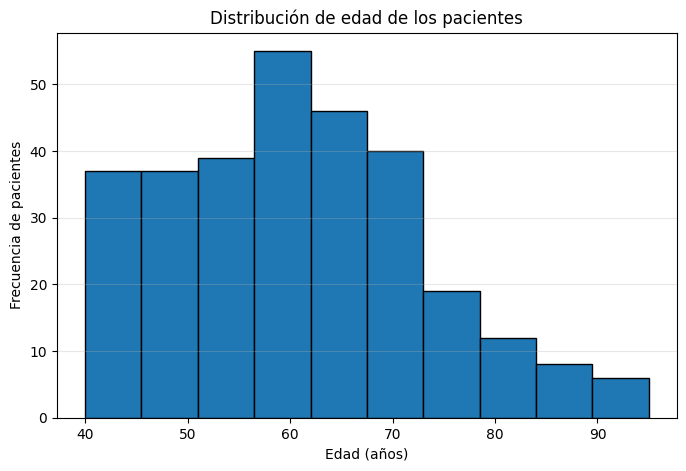

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(df['age'], bins=10, edgecolor='black')

plt.title('Distribución de edad de los pacientes')
plt.xlabel('Edad (años)')
plt.ylabel('Frecuencia de pacientes')

plt.grid(axis='y', alpha=0.3)
plt.show()

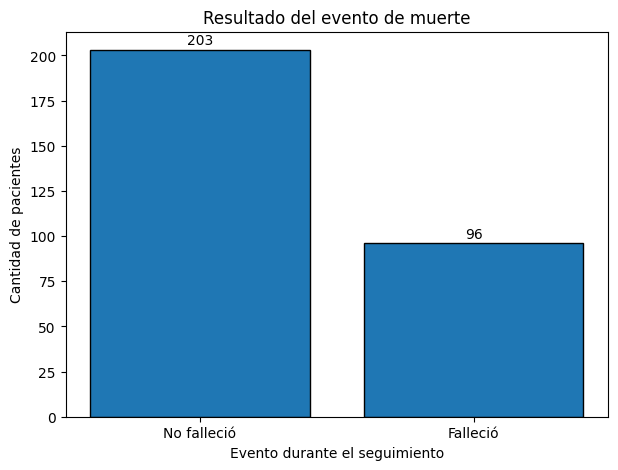

In [14]:
conteo = df['DEATH_EVENT'].value_counts().sort_index()

etiquetas = ['No falleció', 'Falleció']

plt.figure(figsize=(7, 5))
plt.bar(etiquetas, conteo.values, edgecolor='black')

plt.title('Resultado del evento de muerte')
plt.xlabel('Evento durante el seguimiento')
plt.ylabel('Cantidad de pacientes')

for i, valor in enumerate(conteo.values):
    plt.text(i, valor + 3, str(valor), ha='center')

plt.show()

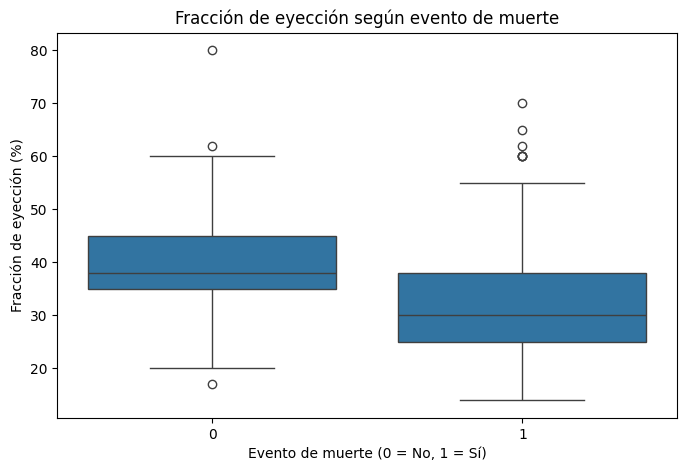

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='DEATH_EVENT',
    y='ejection_fraction'
)

plt.title('Fracción de eyección según evento de muerte')
plt.xlabel('Evento de muerte (0 = No, 1 = Sí)')
plt.ylabel('Fracción de eyección (%)')

plt.show()

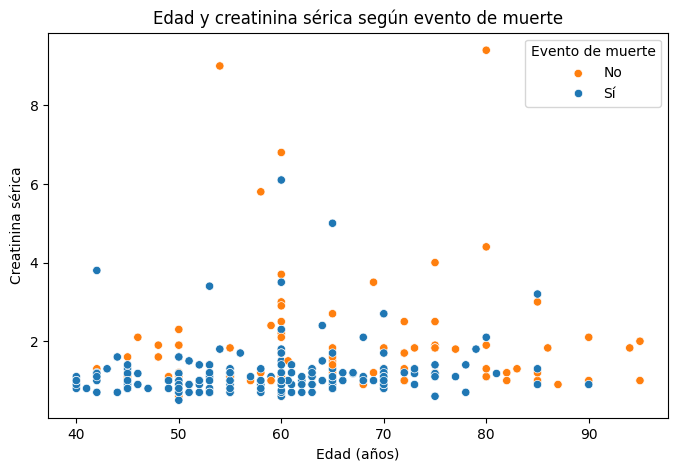

In [16]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='age',
    y='serum_creatinine',
    hue='DEATH_EVENT'
)

plt.title('Edad y creatinina sérica según evento de muerte')
plt.xlabel('Edad (años)')
plt.ylabel('Creatinina sérica')

plt.legend(title='Evento de muerte', labels=['No', 'Sí'])
plt.show()

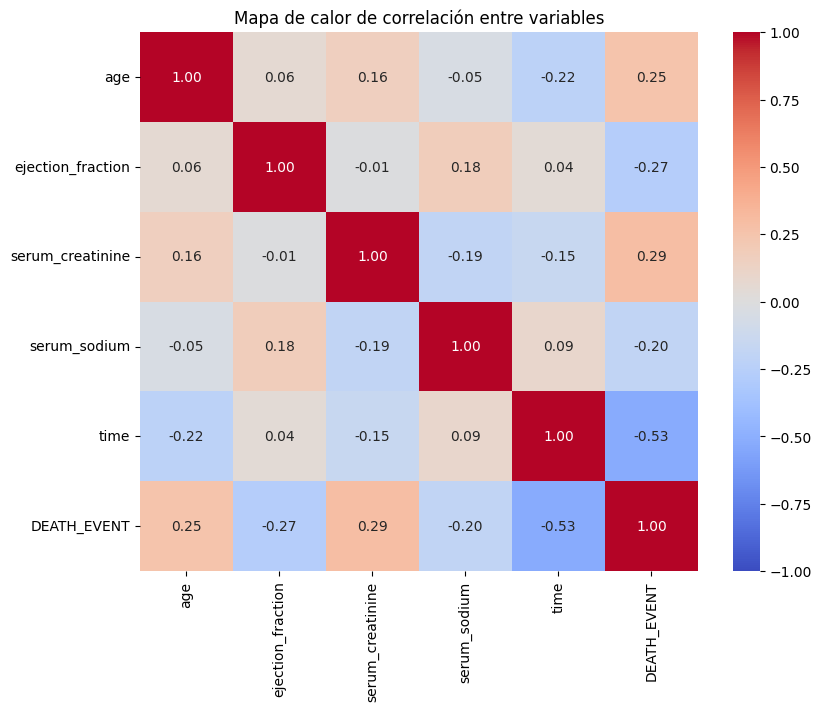

In [17]:
variables_corr = [
    'age',
    'ejection_fraction',
    'serum_creatinine',
    'serum_sodium',
    'time',
    'DEATH_EVENT'
]

correlacion = df[variables_corr].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlacion,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Mapa de calor de correlación entre variables')
plt.show()